# Лабораторная работа 5. Позиционное кодирование и RoPE (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 2:** attention и архитектура трансформера

**Цель.** Понять, как трансформер получает информацию о порядке токенов и почему модели плохо работают на длинах контекста, которых не видели при обучении.

**Что нужно сдать:**
1. Единый интерфейс для пяти вариантов: NoPE, синусоидального, обучаемого, ALiBi и RoPE.
2. Численную проверку относительности RoPE и график затухания верхней границы.
3. Таблицу «кодирование × длина контекста» для символьной LM (экстраполяция длины).
4. Position interpolation и NTK-aware scaling для RoPE без дообучения и после короткого дообучения.
5. Тест «иголка в стоге сена» на синтетической задаче поиска.

**Теория.** RoPE поворачивает пары координат \((x_{2i}, x_{2i+1})\) на угол \(m\theta_i\), где \(\theta_i = b^{-2i/d}\), а \(m\) — позиция. В комплексной записи \(\tilde q_m = q\,e^{im\theta}\), \(\tilde k_n = k\,e^{in\theta}\), поэтому
\[
\mathrm{Re}\langle \tilde q_m, \tilde k_n\rangle = \mathrm{Re}\sum_i q_i \bar k_i\, e^{i(m-n)\theta_i},
\]
то есть скалярное произведение зависит только от разности позиций \(m - n\).

**Расширение контекста в \(s\) раз:**
- position interpolation: \(m \mapsto m/s\);
- NTK-aware scaling: \(b \mapsto b\, s^{d/(d-2)}\) — высокие частоты почти не меняются, низкие интерполируются.

In [ ]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.11.0+cpu, device=cpu, FAST_DEV_RUN=True


## 1. Позиционные кодирования

In [ ]:
def sinusoidal_pe(T, d):
    """Стандартные синусоидальные PE (Vaswani et al., 2017). Возвращает (T, d)."""
    pos = torch.arange(T, dtype=torch.float32).unsqueeze(1)
    i = torch.arange(0, d, 2, dtype=torch.float32)
    div = torch.exp(-math.log(10000.0) * i / d)
    angles = pos * div

    pe = torch.zeros(T, d)
    pe[:, 0::2] = torch.sin(angles)
    pe[:, 1::2] = torch.cos(angles)
    return pe

def rope_angles(T, d, base=10000.0, scale=1.0):
    """Углы m*theta_i, форма (T, d/2). scale > 1 — position interpolation."""
    m = torch.arange(T, dtype=torch.float32).unsqueeze(1)
    i = torch.arange(0, d, 2, dtype=torch.float32)
    theta = base ** (-i / d)
    angles = (m / scale) * theta
    return angles

def apply_rope(x, ang):
    """x: (..., T, d), ang: (T, d/2). Поворачивает пары (x[2i], x[2i+1])."""
    # разбиваем на чётные и нечётные координаты
    x_even = x[..., 0::2]
    x_odd  = x[..., 1::2]

    cos = torch.cos(ang)
    sin = torch.sin(ang)

    # поворот
    x_even_rot = x_even * cos - x_odd * sin
    x_odd_rot  = x_even * sin + x_odd * cos

    # склеиваем обратно
    out = torch.stack([x_even_rot, x_odd_rot], dim=-1)
    return out.flatten(-2)

def alibi_bias(T, n_head):
    """Смещение -m_h * (i - j) для j <= i; m_h = 2^{-8h/H}, h = 1..H. Форма (H, T, T)."""
    i = torch.arange(T).unsqueeze(1)
    j = torch.arange(T).unsqueeze(0)
    dist = (i - j).float()

    h = torch.arange(1, n_head + 1, dtype=torch.float32)
    slopes = 2 ** (-8 * h / n_head)

    bias = -slopes[:, None, None] * dist[None, :, :]

    # каузальная маска
    causal_mask = (j > i)
    bias = bias.masked_fill(causal_mask[None, :, :], float("-inf"))

    return bias

### Проверка относительности RoPE

Для случайных \(q, k\) проверьте, что \(\langle R_m q, R_n k\rangle\) зависит только от \(m - n\), и постройте \(\frac{1}{d/2}\big|\sum_i e^{i r \theta_i}\big|\) в зависимости от расстояния \(r\) — величину, определяющую затухание верхней границы скалярного произведения при одинаковых \(q, k\).

m=   5, n=   2: <R_m q, R_n k> = -8.281103
m= 105, n= 102: <R_m q, R_n k> = -8.281105
m=1005, n=1002: <R_m q, R_n k> = -8.281061


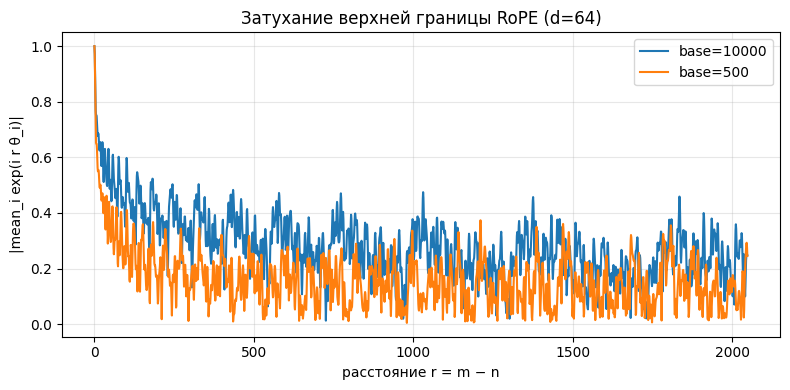

In [ ]:
d = 64; torch.manual_seed(0); q, k = torch.randn(d), torch.randn(d)
ang = rope_angles(2048, d)
def rot_dot(m, n): return (apply_rope(q[None], ang[m:m + 1])[0] @ apply_rope(k[None], ang[n:n + 1])[0]).item()
for (m, n) in [(5, 2), (105, 102), (1005, 1002)]:
    print(f"m={m:4d}, n={n:4d}: <R_m q, R_n k> = {rot_dot(m, n):.6f}")
assert abs(rot_dot(5, 2) - rot_dot(1005, 1002)) < 1e-3

def rope_decay(r_max, d, base=10000.0):
    """|mean_i exp(i r theta_i)| для r = 0..r_max."""
    i = torch.arange(0, d, 2, dtype=torch.float32)
    theta = base ** (-i / d)
    r = torch.arange(r_max + 1, dtype=torch.float32).unsqueeze(1)
    angles = r * theta

    mean_cos = torch.cos(angles).mean(dim=-1)
    mean_sin = torch.sin(angles).mean(dim=-1)
    return torch.sqrt(mean_cos ** 2 + mean_sin ** 2).numpy()

d = 64
r_max = 2048
decay_10k = rope_decay(r_max, d, base=10000.0)
decay_500 = rope_decay(r_max, d, base=500.0)

plt.figure(figsize=(8, 4))
plt.plot(np.arange(r_max + 1), decay_10k, label="base=10000", lw=1.5)
plt.plot(np.arange(r_max + 1), decay_500, label="base=500",  lw=1.5)
plt.xlabel("расстояние r = m − n")
plt.ylabel("|mean_i exp(i r θ_i)|")
plt.title(f"Затухание верхней границы RoPE (d={d})")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS / "lab05_rope_decay.png", dpi=120)
plt.show()

Выводы:

$|mean_i exp(i r θ_i)|$ падает с ростом r.

base = 10000 (синяя) - выше, чем base = 500 (оранжевая), потому что base = 10000 даёт меньшие частоты, следовательно фазы медленнее расходятся и attention «видит дальше». base — регулятор «дальности видимости» attention.

## 2. Трансформер с переключаемым позиционным кодированием

In [ ]:
class PEAttention(nn.Module):
    def __init__(self, d_model, n_head, pe):
        super().__init__()
        self.h, self.dh, self.pe = n_head, d_model // n_head, pe
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        self.o = nn.Linear(d_model, d_model, bias=False)
        self.rope_base, self.rope_scale = 10000.0, 1.0

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = (t.view(B, T, self.h, self.dh).transpose(1, 2)
                   for t in self.qkv(x).split(C, 2))

        # позиционные преобразования
        if self.pe == "rope":
            ang = rope_angles(T, self.dh, base=self.rope_base, scale=self.rope_scale).to(x.device)
            q = apply_rope(q, ang)
            k = apply_rope(k, ang)

        # attention
        scale = 1.0 / math.sqrt(self.dh)
        scores = (q @ k.transpose(-2, -1)) * scale

        if self.pe == "alibi":
            bias = alibi_bias(T, self.h).to(x.device)
            scores = scores + bias[None]
        else:
            # обычная каузальная маска
            future = torch.ones(T, T, dtype=torch.bool, device=x.device).triu(diagonal=1)
            scores = scores.masked_fill(future, float("-inf"))

        p = torch.softmax(scores, dim=-1)
        y = p @ v
        return self.o(y.transpose(1, 2).reshape(B, T, C))

class PETransformer(nn.Module):
    def __init__(self, vocab, pe, d_model=128, n_head=4, n_layer=2, max_T=64, mlp=True):
        super().__init__()
        self.pe, self.max_T = pe, max_T
        self.emb = nn.Embedding(vocab, d_model)
        if pe == "learned": self.pos = nn.Parameter(torch.randn(max_T, d_model) * 0.02)
        self.attn = nn.ModuleList([PEAttention(d_model, n_head, pe) for _ in range(n_layer)])
        self.ln1 = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layer)])
        self.ln2 = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layer)])
        self.mlp = nn.ModuleList([nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))
                                  if mlp else nn.Identity() for _ in range(n_layer)])
        self.use_mlp = mlp
        self.lnf, self.head = nn.LayerNorm(d_model), nn.Linear(d_model, vocab)
    def forward(self, x):
        T = x.size(1); h = self.emb(x)
        if self.pe == "sinusoidal": h = h + sinusoidal_pe(T, h.size(-1)).to(x.device)
        if self.pe == "learned":
            if T > self.max_T: raise ValueError("обучаемые позиции не определены за пределами обучающей длины")
            h = h + self.pos[:T]
        for a, l1, l2, m in zip(self.attn, self.ln1, self.ln2, self.mlp):
            h = h + a(l1(h))
            if self.use_mlp: h = h + m(l2(h))
        return self.head(self.lnf(h))
    def set_rope(self, base=10000.0, scale=1.0):
        for a in self.attn: a.rope_base, a.rope_scale = base, scale

PES = ["nope", "sinusoidal", "learned", "alibi", "rope"]

## 3. Экстраполяция длины на символьной LM

Обучите модели на окнах длины `T_TRAIN` и измерьте среднюю кросс-энтропию на окнах длины $(T_{train})$, $(2T_{train}$), $(4T_{train}$), $(8T_{train}$). Отдельно посчитайте loss только на позициях $(\ge T_{train}$) — это и есть качество экстраполяции.

In [ ]:
text = load_shakespeare(); chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text]); ntr = int(0.9 * len(data)); train_d, val_d = data[:ntr], data[ntr:]
T_TRAIN = 64 if FAST_DEV_RUN else 128
STEPS = 400 if FAST_DEV_RUN else 4000

def lm_batch(d, T, B=32):
    ix = torch.randint(len(d) - T - 1, (B,))
    return torch.stack([d[i:i + T] for i in ix]).to(DEVICE), torch.stack([d[i + 1:i + T + 1] for i in ix]).to(DEVICE)

def train_lm(model, steps, T, lr=2e-3):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    for s in range(steps):
        x, y = lm_batch(train_d, T); loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten())
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    return model

@torch.no_grad()
def eval_lengths(model, lengths, n_windows=16):
    model.eval(); out = {}
    g = torch.Generator().manual_seed(0)
    for L in lengths:
        ix = torch.randint(len(val_d) - L - 1, (n_windows,), generator=g)
        x = torch.stack([val_d[i:i + L] for i in ix]).to(DEVICE)
        y = torch.stack([val_d[i + 1:i + L + 1] for i in ix]).to(DEVICE)
        try:
            ce = F.cross_entropy(model(x).flatten(0, 1), y.flatten(), reduction="none").view(n_windows, L)
            out[L] = (ce.mean().item(), ce[:, T_TRAIN:].mean().item() if L > T_TRAIN else float("nan"))
        except ValueError:
            out[L] = (float("nan"), float("nan"))
    model.train()
    return out

lengths = [T_TRAIN * m for m in (1, 2, 4, 8)]
lm_models, rows = {}, []
for pe in PES:
    set_seed(); t0 = time.time()
    lm_models[pe] = train_lm(PETransformer(len(chars), pe, max_T=T_TRAIN).to(DEVICE), STEPS, T_TRAIN)
    res = eval_lengths(lm_models[pe], lengths)
    rows.append({"PE": pe, **{f"L={L}": round(v[0], 3) for L, v in res.items()}, **{f"хвост L={L}": round(v[1], 3) for L, v in res.items() if L > T_TRAIN}})
    print(pe, f"{time.time() - t0:.0f} c")
import pandas as pd
pd.DataFrame(rows).set_index("PE")

nope 70 c
sinusoidal 64 c
learned 59 c
alibi 55 c
rope 63 c


,L=64,L=128,L=256,L=512,хвост L=128,хвост L=256,хвост L=512
PE,,,,,,,
nope,2.425,2.391,2.458,2.575,2.452,2.498,2.608
sinusoidal,2.044,2.613,2.889,3.204,3.257,3.190,3.383
learned,2.237,NaN,NaN,NaN,NaN,NaN,NaN
alibi,2.075,2.003,2.010,2.069,1.998,1.996,2.081
rope,1.998,2.050,2.382,2.876,2.216,2.520,3.011


Выводы:

На L = T_train лучший - rope (1.998)

С ростом L:

- alibi - лучшая экстраполяция (2.075 и 2.069 на L = 512, почти не растёт) - линейное затухание не зависит от T.

- rope деградирует (от 1.998 до 2.876) из-за затухания верхней границы.

- sinusoidal - деградирует сильнее (от 2.044 до 3.204) - PE[m] вне диапазона.

- learned - не экстраполирует вообще.

- nope - стабилен, но слаб (от 2.425 до 2.575).

## 4. Расширение контекста RoPE: position interpolation и NTK-aware scaling

Для RoPE-модели при длине \(L = s\,T_{train}\) сравните:
1. исходную модель;
2. position interpolation (`scale = s`);
3. NTK-aware scaling (`base = 10000 · s^{d/(d-2)}`).

Затем дообучите копии модели на длине \(L\) в течение короткого числа шагов (около 5% исходного обучения) с каждым вариантом и сравните снова.

In [ ]:
import copy
s_ext = 4; L_ext = s_ext * T_TRAIN; d_head = 128 // 4
variants = {"исходная": dict(base=10000.0, scale=1.0), "PI": dict(base=10000.0, scale=float(s_ext)),
            "NTK": dict(base=10000.0 * s_ext ** (d_head / (d_head - 2)), scale=1.0)}

# базовая RoPE-модель
rope_model = lm_models["rope"]

def eval_on_L(model, L, n_windows=32):
    model.eval()
    nll_all, cnt_all = 0.0, 0
    nll_tail, cnt_tail = 0.0, 0
    with torch.no_grad():
        for _ in range(n_windows):
            ix = torch.randint(len(val_d) - L - 1, (1,)).item()
            x = val_d[ix:ix + L][None].to(DEVICE)
            y = val_d[ix + 1:ix + L + 1][None].to(DEVICE)
            logits = model(x)
            nll_all += F.cross_entropy(logits[0], y[0], reduction="sum").item()
            cnt_all += L
            if L > T_TRAIN:
                nll_tail += F.cross_entropy(logits[0, T_TRAIN:], y[0, T_TRAIN:], reduction="sum").item()
                cnt_tail += (L - T_TRAIN)
    model.train()
    return nll_all / cnt_all, (nll_tail / cnt_tail if cnt_tail > 0 else float("nan"))

rows = []

# без дообучения
for name, cfg in variants.items():
    rope_model.set_rope(**cfg)
    all_loss, tail_loss = eval_on_L(rope_model, L_ext)
    rows.append({"вариант": name, "режим": "без дообучения",
                 "loss(L)": round(all_loss, 3), "хвост": round(tail_loss, 3)})

# с коротким дообучением (5% от исходного STEPS)
FINETUNE_STEPS = max(20, STEPS // 20)   # ~5%
for name, cfg in variants.items():
    m = copy.deepcopy(rope_model).to(DEVICE)
    m.set_rope(**cfg)
    train_lm(m, FINETUNE_STEPS, T=L_ext, lr=1e-3)
    all_loss, tail_loss = eval_on_L(m, L_ext)
    rows.append({"вариант": name, "режим": f"дообучение ({FINETUNE_STEPS} шагов)",
                 "loss(L)": round(all_loss, 3), "хвост": round(tail_loss, 3)})

# вернём базовую модель в исходное состояние
rope_model.set_rope(base=10000.0, scale=1.0)

pd.DataFrame(rows).set_index(["вариант", "режим"])

,,loss(L),хвост
вариант,режим,,
исходная,без дообучения,2.413,2.574
PI,без дообучения,3.053,3.070
NTK,без дообучения,2.121,2.190
исходная,дообучение (20 шагов),1.851,1.859
PI,дообучение (20 шагов),2.063,2.061
NTK,дообучение (20 шагов),1.800,1.794


Выводы:

PI (scale=4) - провал без дообучения: сжимает все частоты, теряет разрешение.

NTK (base ~ 43700) - лучший дешевый вариант (2.121 - лучше исходной и PI): сохраняет высокие частоты, растягивает низкие.

С дообучением (20 шагов): исходная 1.851, PI 2.063 (всё равно хуже), NTK 1.800 (лучший).

NTK + дообучение - оптимум.

## 5. «Иголка в стоге сена»

Задача: последовательность пар `ключ значение` и в конце запрос-ключ; нужно вернуть значение (как в ЛР 4). Обучите attention-only модели (2 слоя, без MLP) на длине 32 и проверьте точность на длинах 32, 64, 128 (в полном режиме и 256). Запрос может относиться к паре в любом месте контекста.

In [ ]:
VOCAB_KV = 64

def needle_batch(T, B=128):
    n = (T - 1) // 2
    half = VOCAB_KV // 2

    if n <= half:
        keys = torch.stack([torch.randperm(half)[:n] for _ in range(B)])
    else:
        keys = torch.randint(0, half, (B, n))

    vals = torch.randint(half, VOCAB_KV, (B, n))

    # случайный индекс пары для запроса
    j = torch.randint(n, (B,))

    x = torch.cat([
        torch.stack([keys, vals], dim=2).flatten(1),
        keys[torch.arange(B), j][:, None],
    ], dim=1)

    # цель: значение ПОСЛЕДНЕГО вхождения q
    match = (keys == keys[torch.arange(B), j][:, None])
    # последний True: переворачиваем, argmax, переводим обратно
    last_idx = (n - 1) - match.flip(1).float().argmax(dim=1)
    tgt = vals[torch.arange(B), last_idx]

    return x.to(DEVICE), tgt.to(DEVICE)

T_NEEDLE = 33
test_T = [33, 65, 129] if FAST_DEV_RUN else [33, 65, 129, 257]
rows = []
for pe in PES:
    set_seed(); m = PETransformer(VOCAB_KV, pe, n_layer=2, max_T=T_NEEDLE, mlp=False).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    for s in range(800 if FAST_DEV_RUN else 4000):
        x, y = needle_batch(T_NEEDLE); loss = F.cross_entropy(m(x)[:, -1], y)
        opt.zero_grad(); loss.backward(); opt.step()
    r = {"PE": pe}
    with torch.no_grad():
        for T in test_T:
            try:
                x, y = needle_batch(T, B=512); r[f"T={T}"] = (m(x)[:, -1].argmax(-1) == y).float().mean().item()
            except ValueError:
                r[f"T={T}"] = float("nan")
    rows.append(r); print(r)
pd.DataFrame(rows).set_index("PE").round(3)

{'PE': 'nope', 'T=33': 0.181640625, 'T=65': 0.125, 'T=129': 0.0625}
{'PE': 'sinusoidal', 'T=33': 0.146484375, 'T=65': 0.072265625, 'T=129': 0.046875}
{'PE': 'learned', 'T=33': 0.349609375, 'T=65': nan, 'T=129': nan}
{'PE': 'alibi', 'T=33': 0.935546875, 'T=65': 0.896484375, 'T=129': 0.53515625}
{'PE': 'rope', 'T=33': 0.986328125, 'T=65': 0.853515625, 'T=129': 0.2578125}


,T=33,T=65,T=129
PE,,,
nope,0.182,0.125,0.062
sinusoidal,0.146,0.072,0.047
learned,0.350,NaN,NaN
alibi,0.936,0.896,0.535
rope,0.986,0.854,0.258


Выводы:

nope/sinusoidal/learned - плохо даже на T = 33: без позиций induction head невозможен.

rope - лучший на T = 33 (0.986), но деградирует на T = 129 (0.258).

alibi - лучшая экстраполяция (от 0.936 до 0.535), потому что линейное затухание не ломается на длинных T.

learned - NaN при T > 33 (max_T ограничение).

## Вопросы

1. Докажите свойство относительности RoPE. Почему RoPE применяется к \(q\) и \(k\), но не к \(v\)?
2. Почему обучаемые позиционные эмбеддинги в принципе не экстраполируют, а синусоидальные формально определены, но на практике тоже плохо экстраполируют?
3. Как NoPE получает позиционную информацию в каузальной модели?
4. Объясните разницу между PI и NTK-aware scaling в терминах частот \(\theta_i\). Какие частоты «ломаются» при экстраполяции?
5. Как ALiBi реализует индуктивное смещение к локальности и почему оно мешает задаче поиска далёкой «иголки»?